In [6]:
from google.colab import files
uploaded = files.upload()
DATA_PATH = 'city_day.csv'

Saving city_day.csv to city_day (1).csv


In [7]:
DATA_PATH = list(uploaded.keys())[0]
print(DATA_PATH)

city_day (1).csv


In [8]:
import pandas as pd

# Load the data and turn the Date column into real dates
df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'])

# Size of the full dataset and the exact city spellings
print(df.shape)
print(df['City'].unique())

# Keep only the four cities (check that these spellings match the list printed above)
cities = ['Delhi', 'Bengaluru', 'Kolkata', 'Hyderabad']
df4 = df[df['City'].isin(cities)].copy()

# Sort so each city's days are in time order (needed later for lags)
df4 = df4.sort_values(['City', 'Date']).reset_index(drop=True)

# Size, first rows, and date range per city
print(df4.shape)
print(df4.head())
print(df4.groupby('City')['Date'].agg(['min', 'max', 'count']))

(29531, 16)
['Ahmedabad' 'Aizawl' 'Amaravati' 'Amritsar' 'Bengaluru' 'Bhopal'
 'Brajrajnagar' 'Chandigarh' 'Chennai' 'Coimbatore' 'Delhi' 'Ernakulam'
 'Gurugram' 'Guwahati' 'Hyderabad' 'Jaipur' 'Jorapokhar' 'Kochi' 'Kolkata'
 'Lucknow' 'Mumbai' 'Patna' 'Shillong' 'Talcher' 'Thiruvananthapuram'
 'Visakhapatnam']
(6838, 16)
        City       Date  PM2.5  PM10     NO    NO2    NOx    NH3     CO  \
0  Bengaluru 2015-01-01    NaN   NaN   3.26  17.33  10.88  20.36   0.33   
1  Bengaluru 2015-01-02    NaN   NaN   6.05  19.73  14.14  23.74   1.35   
2  Bengaluru 2015-01-03    NaN   NaN  11.91  19.88  20.72   4.32  17.40   
3  Bengaluru 2015-01-04    NaN   NaN   7.45  21.61  16.88   0.87   5.05   
4  Bengaluru 2015-01-05    NaN   NaN   9.52  22.17  21.76  31.38   1.83   

     SO2     O3  Benzene  Toluene  Xylene  AQI AQI_Bucket  
0   3.54  10.73     0.56     4.64     NaN  NaN        NaN  
1   3.97  22.77     0.65     5.31     NaN  NaN        NaN  
2  13.61  12.03     0.53    19.25     NaN  Na

**Missingness and zeros per city**

In [9]:
pollutants = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO',
              'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI']

# % of missing values per city and column
missing = df4.groupby('City')[pollutants].apply(lambda g: g.isna().mean() * 100).round(1)
print("Missing %:\n", missing.T)

# Number of exact zeros per city and column
zeros = df4.groupby('City')[pollutants].apply(lambda g: (g == 0).sum())
print("\nZero counts:\n", zeros.T)

Missing %:
 City     Bengaluru  Delhi  Hyderabad  Kolkata
PM2.5          7.3    0.1        5.7      6.8
PM10          17.9    3.8       17.7      6.8
NO             0.3    0.1        1.4      3.2
NO2            0.3    0.1        1.4      3.1
NOx            0.2    0.0        0.3      0.1
NH3           10.1    0.4       17.9      0.0
CO             0.5    0.0        0.2      0.0
SO2            0.3    5.5        1.3      7.6
O3             7.2    4.2        1.3      6.1
Benzene       13.2    0.0        6.3      0.1
Toluene        4.6    0.0        6.3      0.1
Xylene       100.0   38.9        6.3     51.6
AQI            4.9    0.5        6.3      7.4

Zero counts:
 City     Bengaluru  Delhi  Hyderabad  Kolkata
PM2.5            0      0          0        0
PM10             0      0          0        0
NO               0      0          0        0
NO2              0      0          0        0
NOx            337      2         21        0
NH3              0      0          0        0
CO     

In [10]:
# 1. Is CO exactly equal to NO? (only on rows where both are present)
both = df4.dropna(subset=['CO', 'NO'])
co_eq_no = both.groupby('City').apply(lambda g: (g['CO'] == g['NO']).mean() * 100).round(1)
print("% of rows where CO == NO:\n", co_eq_no)

# 2. NOx zero while NO or NO2 is positive (physically impossible)
bad_nox = df4[(df4['NOx'] == 0) & ((df4['NO'] > 0) | (df4['NO2'] > 0))]
print("\nImpossible NOx zeros per city:\n", bad_nox['City'].value_counts())

% of rows where CO == NO:
 City
Bengaluru    0.0
Delhi        0.0
Hyderabad    0.0
Kolkata      0.0
dtype: float64

Impossible NOx zeros per city:
 City
Bengaluru    337
Name: count, dtype: int64


/tmp/ipykernel_599/146489173.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  co_eq_no = both.groupby('City').apply(lambda g: (g['CO'] == g['NO']).mean() * 100).round(1)


**Category distribution and an AQI-over-time plot**

AQI_Bucket  Good  Satisfactory  Moderate  Poor  Very Poor  Severe
City                                                             
Bengaluru    115          1124       630    36          5       0
Delhi         21           158       519   542        520     239
Hyderabad    141           710       958    54         10       7
Kolkata      119           285       152   119         66      13


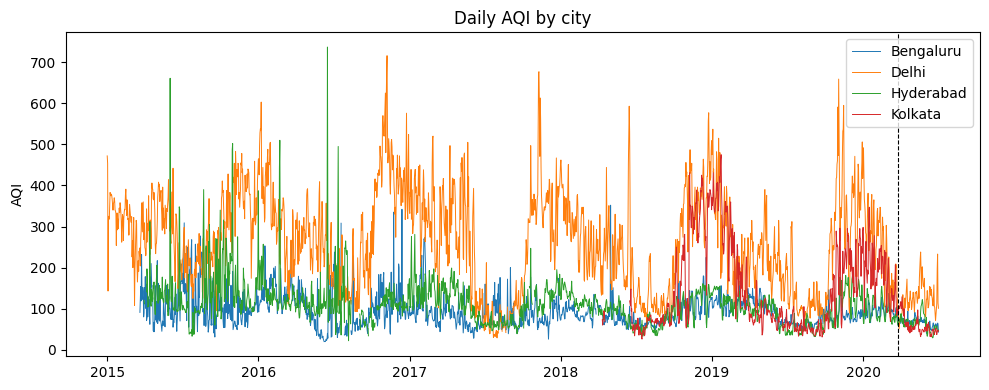

In [11]:
import matplotlib.pyplot as plt

# How many days fall in each AQI category, per city
order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
buckets = pd.crosstab(df4['City'], df4['AQI_Bucket'])[order]
print(buckets)

# Daily AQI over time, one line per city
fig, ax = plt.subplots(figsize=(10, 4))
for city, g in df4.groupby('City'):
    ax.plot(g['Date'], g['AQI'], label=city, linewidth=0.7)
ax.axvline(pd.Timestamp('2020-03-25'), color='k', linestyle='--', linewidth=0.8)  # lockdown start
ax.set_ylabel('AQI'); ax.legend(); ax.set_title('Daily AQI by city')
plt.tight_layout()
plt.savefig('fig_aqi_timeseries.png', dpi=200)
plt.show()

**Clean the data and save it**

In [12]:
import os
import numpy as np

clean = df4.copy()

# 1. Drop Xylene (mostly missing; not in the proposal)
clean = clean.drop(columns=['Xylene'])

# 2. Treat suspicious zeros as missing
for col in ['NOx', 'CO', 'Benzene', 'Toluene']:
    clean.loc[clean[col] == 0, col] = np.nan

# 3. Quick check: these columns should now show no zeros
print((clean[['NOx', 'CO', 'Benzene', 'Toluene']] == 0).sum())
print(clean.shape)

# 4. Save to Drive so it survives Colab resets
os.makedirs('/content/drive/MyDrive/aqi_project', exist_ok=True)
clean.to_csv('/content/drive/MyDrive/aqi_project/clean_4cities.csv', index=False)

NOx        0
CO         0
Benzene    0
Toluene    0
dtype: int64
(6838, 15)


**Target and features**

In [13]:
clean = pd.read_csv('/content/drive/MyDrive/aqi_project/clean_4cities.csv', parse_dates=['Date'])
clean = clean.sort_values(['City', 'Date']).reset_index(drop=True)

pollutants = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO',
              'SO2', 'O3', 'Benzene', 'Toluene']
vars_to_lag = ['AQI'] + pollutants
g = clean.groupby('City')

# Target: tomorrow's AQI, within each city
clean['target'] = g['AQI'].shift(-1)
clean['target_date'] = clean['Date'] + pd.Timedelta(days=1)

# Lags 0..6 (lag 0 = today)
for v in vars_to_lag:
    for k in range(7):
        clean[f'{v}_lag{k}'] = g[v].shift(k)

# Rolling means of AQI and PM2.5 over the last 3 and 7 days, ending today
for v in ['AQI', 'PM2.5']:
    for w in [3, 7]:
        clean[f'{v}_roll{w}'] = g[v].transform(lambda s: s.rolling(w, min_periods=1).mean())

# Calendar features of the target day
clean['month'] = clean['target_date'].dt.month
clean['dow'] = clean['target_date'].dt.dayofweek

# City one-hot
clean = pd.concat([clean, pd.get_dummies(clean['City'], prefix='city', dtype=int)], axis=1)

# Drop rows with no target
data = clean.dropna(subset=['target']).reset_index(drop=True)
print(data.shape)

# Sanity check: target on day t should equal AQI on day t+1
print(clean.loc[clean['City'] == 'Delhi', ['Date', 'AQI', 'target', 'AQI_lag1']].iloc[5:9])

(6542, 111)
           Date    AQI  target  AQI_lag1
2014 2015-01-06  318.0   353.0     325.0
2015 2015-01-07  353.0   383.0     318.0
2016 2015-01-08  383.0   375.0     353.0
2017 2015-01-09  375.0   376.0     383.0


**Chronological split and the feature list**

In [14]:
exclude = ['City', 'Date', 'target', 'target_date', 'AQI_Bucket', 'AQI'] + pollutants
features = [c for c in data.columns if c not in exclude]
print(len(features))   # should be 94

train = data[data['target_date'] <= '2018-12-31']
val   = data[(data['target_date'] >= '2019-01-01') & (data['target_date'] <= '2019-12-31')]
test  = data[data['target_date'] >= '2020-01-01']

for name, part in [('train', train), ('val', val), ('test', test)]:
    print(name, part.shape[0], part['target_date'].min().date(), part['target_date'].max().date())
    print(part['City'].value_counts().to_dict())

# Save so later notebooks don't need to rebuild features
data.to_pickle('/content/drive/MyDrive/aqi_project/features.pkl')

94
train 4350 2015-01-02 2018-12-31
{'Delhi': 1450, 'Bengaluru': 1362, 'Hyderabad': 1332, 'Kolkata': 206}
val 1460 2019-01-01 2019-12-31
{'Bengaluru': 365, 'Delhi': 365, 'Hyderabad': 365, 'Kolkata': 365}
test 732 2020-01-01 2020-07-01
{'Bengaluru': 183, 'Delhi': 183, 'Hyderabad': 183, 'Kolkata': 183}


**Metrics function and the two baselines**

In [17]:
import numpy as np
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             f1_score, recall_score, precision_score)

bins = [-np.inf, 50, 100, 200, 300, 400, np.inf]
labels = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
to_cat = lambda x: pd.cut(pd.Series(x), bins=bins, labels=labels).astype(str)

def evaluate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    ct, cp = to_cat(y_true), to_cat(y_pred)
    poor_true, poor_pred = y_true > 200, y_pred > 200
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MacroF1': f1_score(ct, cp, labels=sorted(ct.unique()), average='macro', zero_division=0),
        'PoorRecall': recall_score(poor_true, poor_pred, zero_division=0) if poor_true.sum() > 0 else np.nan,
        'PoorPrecision': precision_score(poor_true, poor_pred, zero_division=0) if poor_true.sum() > 0 else np.nan,
        'n_poor': int(poor_true.sum()),
    }

In [18]:
# Persistence: today's AQI, or the most recent available lag if today's is missing
lag_cols = [f'AQI_lag{k}' for k in range(7)]
def persistence(df):
    return df[lag_cols].bfill(axis=1).iloc[:, 0]

# Seasonal mean: train-period mean target per (city, month), with a pooled-month fallback
city_month = train.groupby(['City', 'month'])['target'].mean()
month_mean = train.groupby('month')['target'].mean()
def seasonal(df):
    keys = list(zip(df['City'], df['month']))
    return pd.Series([city_month.get(k, month_mean[k[1]]) for k in keys], index=df.index)

# Evaluate on VALIDATION only
rows = []
for name, fn in [('Persistence', persistence), ('Seasonal', seasonal)]:
    pred = fn(val)
    rows.append({'method': name, 'city': 'All', **evaluate(val['target'], pred)})
    for city, part in val.groupby('City'):
        rows.append({'method': name, 'city': city, **evaluate(part['target'], pred[part.index])})
baseline_val = pd.DataFrame(rows).round(3)
print(baseline_val)

        method       city     MAE    RMSE  MacroF1  PoorRecall  PoorPrecision  \
0  Persistence        All  19.998  33.130    0.723       0.846          0.846   
1  Persistence  Bengaluru   9.507  13.285    0.629         NaN            NaN   
2  Persistence      Delhi  38.482  53.988    0.662       0.845          0.845   
3  Persistence  Hyderabad  10.118  14.248    0.844         NaN            NaN   
4  Persistence    Kolkata  21.885  33.107    0.691       0.848          0.848   
5     Seasonal        All  46.322  65.457    0.372       0.949          0.707   
6     Seasonal  Bengaluru  20.913  25.067    0.416         NaN            NaN   
7     Seasonal      Delhi  73.158  92.533    0.334       0.974          0.692   
8     Seasonal  Hyderabad  31.605  37.796    0.364         NaN            NaN   
9     Seasonal    Kolkata  59.611  80.742    0.271       0.899          0.742   

   n_poor  
0     293  
1       0  
2     194  
3       0  
4      99  
5     293  
6       0  
7     194  


In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

X_tr, y_tr = train[features], train['target']
X_va, y_va = val[features], val['target']

ridge_scores = {}
for a in [0.1, 1, 10, 100, 1000]:
    model = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=a))
    model.fit(X_tr, y_tr)
    ridge_scores[a] = mean_absolute_error(y_va, model.predict(X_va))
print(ridge_scores)

best_alpha = min(ridge_scores, key=ridge_scores.get)
ridge = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=best_alpha))
ridge.fit(X_tr, y_tr)
pred = ridge.predict(X_va)

print("Best alpha:", best_alpha)
print("All:", {k: round(v, 3) for k, v in evaluate(y_va, pred).items()})
for city, part in val.groupby('City'):
    r = evaluate(part['target'], pred[val.index.get_indexer(part.index)])
    print(city, {k: round(v, 3) for k, v in r.items()})

{0.1: 16.880397676576095, 1: 16.884963980895797, 10: 16.902861449990564, 100: 17.039177155078626, 1000: 19.055389164061612}
Best alpha: 0.1
All: {'MAE': 16.88, 'RMSE': np.float64(26.307), 'MacroF1': 0.746, 'PoorRecall': 0.911, 'PoorPrecision': 0.867, 'n_poor': 293}
Bengaluru {'MAE': 7.534, 'RMSE': np.float64(10.288), 'MacroF1': 0.597, 'PoorRecall': nan, 'PoorPrecision': nan, 'n_poor': 0}
Delhi {'MAE': 30.886, 'RMSE': np.float64(42.247), 'MacroF1': 0.708, 'PoorRecall': 0.938, 'PoorPrecision': 0.85, 'n_poor': 194}
Hyderabad {'MAE': 9.413, 'RMSE': np.float64(12.305), 'MacroF1': 0.778, 'PoorRecall': nan, 'PoorPrecision': nan, 'n_poor': 0}
Kolkata {'MAE': 19.688, 'RMSE': np.float64(26.949), 'MacroF1': 0.719, 'PoorRecall': 0.859, 'PoorPrecision': 0.904, 'n_poor': 99}


**Random Forest**

In [20]:
from sklearn.ensemble import RandomForestRegressor
import itertools

def report(name, pred, df=val):
    pred = pd.Series(np.asarray(pred), index=df.index)
    rows = [{'method': name, 'city': 'All', **evaluate(df['target'], pred)}]
    for city, part in df.groupby('City'):
        rows.append({'method': name, 'city': city, **evaluate(part['target'], pred[part.index])})
    return pd.DataFrame(rows).round(3)

val_preds = {'Persistence': persistence(val), 'Seasonal': seasonal(val), 'Ridge': ridge.predict(X_va)}

rf_scores = {}
for leaf, mf in itertools.product([1, 5, 10], ['sqrt', 0.5, 1.0]):
    model = make_pipeline(SimpleImputer(strategy='median'),
                          RandomForestRegressor(n_estimators=300, min_samples_leaf=leaf,
                                                max_features=mf, n_jobs=-1, random_state=42))
    model.fit(X_tr, y_tr)
    rf_scores[(leaf, mf)] = mean_absolute_error(y_va, model.predict(X_va))
    print(leaf, mf, round(rf_scores[(leaf, mf)], 3))

best_leaf, best_mf = min(rf_scores, key=rf_scores.get)
rf = make_pipeline(SimpleImputer(strategy='median'),
                   RandomForestRegressor(n_estimators=300, min_samples_leaf=best_leaf,
                                         max_features=best_mf, n_jobs=-1, random_state=42))
rf.fit(X_tr, y_tr)
val_preds['RandomForest'] = rf.predict(X_va)

print("Best:", best_leaf, best_mf)
print(report('RandomForest', val_preds['RandomForest']))

1 sqrt 18.451
1 0.5 17.288
1 1.0 17.878
5 sqrt 18.632
5 0.5 16.973
5 1.0 17.224
10 sqrt 18.898
10 0.5 16.869
10 1.0 16.648
Best: 10 1.0
         method       city     MAE    RMSE  MacroF1  PoorRecall  \
0  RandomForest        All  16.648  26.412    0.750       0.928   
1  RandomForest  Bengaluru   8.388  11.493    0.596         NaN   
2  RandomForest      Delhi  29.776  41.924    0.727       0.959   
3  RandomForest  Hyderabad   8.108  11.026    0.849         NaN   
4  RandomForest    Kolkata  20.320  27.910    0.670       0.869   

   PoorPrecision  n_poor  
0          0.853     293  
1            NaN       0  
2          0.842     194  
3            NaN       0  
4          0.878      99  


**Larger leaves for the random forest**

In [21]:
for leaf, mf in itertools.product([20, 40], [0.5, 1.0]):
    model = make_pipeline(SimpleImputer(strategy='median'),
                          RandomForestRegressor(n_estimators=300, min_samples_leaf=leaf,
                                                max_features=mf, n_jobs=-1, random_state=42))
    model.fit(X_tr, y_tr)
    rf_scores[(leaf, mf)] = mean_absolute_error(y_va, model.predict(X_va))
    print(leaf, mf, round(rf_scores[(leaf, mf)], 3))

best_leaf, best_mf = min(rf_scores, key=rf_scores.get)
print("Best overall:", best_leaf, best_mf, round(rf_scores[(best_leaf, best_mf)], 3))

rf = make_pipeline(SimpleImputer(strategy='median'),
                   RandomForestRegressor(n_estimators=300, min_samples_leaf=best_leaf,
                                         max_features=best_mf, n_jobs=-1, random_state=42))
rf.fit(X_tr, y_tr)
val_preds['RandomForest'] = rf.predict(X_va)
print(report('RandomForest', val_preds['RandomForest']))

20 0.5 16.88
20 1.0 16.616
40 0.5 17.323
40 1.0 17.01
Best overall: 20 1.0 16.616
         method       city     MAE    RMSE  MacroF1  PoorRecall  \
0  RandomForest        All  16.616  26.610    0.758       0.932   
1  RandomForest  Bengaluru   8.331  11.469    0.596         NaN   
2  RandomForest      Delhi  30.038  42.266    0.721       0.948   
3  RandomForest  Hyderabad   8.253  11.247    0.852         NaN   
4  RandomForest    Kolkata  19.842  28.069    0.702       0.899   

   PoorPrecision  n_poor  
0          0.856     293  
1            NaN       0  
2          0.856     194  
3            NaN       0  
4          0.856      99  


**CatBoost**

In [22]:
!pip install -q catboost
from catboost import CatBoostRegressor

cb_scores, cb_iters = {}, {}
for depth in [4, 6, 8]:
    model = CatBoostRegressor(iterations=2000, learning_rate=0.05, depth=depth,
                              loss_function='RMSE', eval_metric='MAE',
                              random_seed=42, verbose=0)
    model.fit(X_tr, y_tr, eval_set=(X_va, y_va), early_stopping_rounds=100, use_best_model=True)
    cb_scores[depth] = mean_absolute_error(y_va, model.predict(X_va))
    cb_iters[depth] = model.get_best_iteration()
    print(depth, round(cb_scores[depth], 3), "best iteration:", cb_iters[depth])

best_depth = min(cb_scores, key=cb_scores.get)
cb = CatBoostRegressor(iterations=cb_iters[best_depth] + 1, learning_rate=0.05, depth=best_depth,
                       loss_function='RMSE', random_seed=42, verbose=0)
cb.fit(X_tr, y_tr)
val_preds['CatBoost'] = cb.predict(X_va)
print("Best depth:", best_depth)
print(report('CatBoost', val_preds['CatBoost']))

4 16.898 best iteration: 709
6 17.028 best iteration: 793
8 16.812 best iteration: 962
Best depth: 8
     method       city     MAE    RMSE  MacroF1  PoorRecall  PoorPrecision  \
0  CatBoost        All  16.812  26.477    0.742       0.942          0.871   
1  CatBoost  Bengaluru   8.057  10.785    0.599         NaN            NaN   
2  CatBoost      Delhi  29.288  41.882    0.770       0.948          0.872   
3  CatBoost  Hyderabad   8.996  11.825    0.840         NaN            NaN   
4  CatBoost    Kolkata  20.908  28.175    0.594       0.929          0.868   

   n_poor  
0     293  
1       0  
2     194  
3       0  
4      99  


In [23]:
test = test.copy()
test['period'] = np.where(test['target_date'] < '2020-03-25', 'Pre-lockdown', 'Lockdown')

trainval = pd.concat([train, val])
X_tv, y_tv = trainval[features], trainval['target']
X_te, y_te = test[features], test['target']

# Refit with the chosen hyperparameters
ridge_f = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=best_alpha)).fit(X_tv, y_tv)
rf_f = make_pipeline(SimpleImputer(strategy='median'),
                     RandomForestRegressor(n_estimators=300, min_samples_leaf=best_leaf, max_features=best_mf,
                                           n_jobs=-1, random_state=42)).fit(X_tv, y_tv)
cb_f = CatBoostRegressor(iterations=cb_iters[best_depth] + 1, learning_rate=0.05, depth=best_depth,
                         loss_function='RMSE', random_seed=42, verbose=0).fit(X_tv, y_tv)

# Seasonal mean recomputed on 2015-2019
city_month = trainval.groupby(['City', 'month'])['target'].mean()
month_mean = trainval.groupby('month')['target'].mean()

test_preds = {
    'Persistence': persistence(test).values,
    'Seasonal': seasonal(test).values,
    'Ridge': ridge_f.predict(X_te),
    'RandomForest': rf_f.predict(X_te),
    'CatBoost': cb_f.predict(X_te),
}

rows = []
for m, p in test_preds.items():
    p = pd.Series(p, index=test.index)
    for per, part in [('All', test), ('Pre-lockdown', test[test.period == 'Pre-lockdown']),
                      ('Lockdown', test[test.period == 'Lockdown'])]:
        for city, sub in [('All', part)] + list(part.groupby('City')):
            rows.append({'method': m, 'period': per, 'city': city, **evaluate(sub['target'], p[sub.index])})
res = pd.DataFrame(rows).round(3)
res.to_csv('/content/drive/MyDrive/aqi_project/test_results.csv', index=False)

order = ['Seasonal', 'Persistence', 'Ridge', 'RandomForest', 'CatBoost']
print("MAE by period (all cities):\n", res[res.city == 'All'].pivot(index='method', columns='period', values='MAE').loc[order])
print("\nMAE by city (whole test):\n", res[res.period == 'All'].pivot(index='method', columns='city', values='MAE').loc[order])
print("\nPoor-or-worse, all cities:\n", res[res.city == 'All'][['method', 'period', 'MacroF1', 'PoorRecall', 'PoorPrecision', 'n_poor']])

MAE by period (all cities):
 period           All  Lockdown  Pre-lockdown
method                                      
Seasonal      57.288    58.390        55.988
Persistence   16.745    10.018        24.673
Ridge         13.838    10.129        18.209
RandomForest  14.186     9.547        19.655
CatBoost      13.965     9.934        18.716

MAE by city (whole test):
 city             All  Bengaluru    Delhi  Hyderabad  Kolkata
method                                                      
Seasonal      57.288     22.985  104.572     43.686   57.907
Persistence   16.745      7.781   29.574      9.087   20.536
Ridge         13.838      6.424   24.426      8.549   15.953
RandomForest  14.186      7.448   23.771      8.365   17.162
CatBoost      13.965      7.050   22.983      9.076   16.750

Poor-or-worse, all cities:
           method        period  MacroF1  PoorRecall  PoorPrecision  n_poor
0    Persistence           All    0.727       0.777          0.760      94
5    Persistence  Pre-

In [24]:
import pickle
state = {
    'val_preds': val_preds, 'test_preds': test_preds,
    'best_alpha': best_alpha, 'best_leaf': best_leaf, 'best_mf': best_mf,
    'best_depth': best_depth, 'cb_iters': cb_iters, 'features': features,
}
with open('/content/drive/MyDrive/aqi_project/state.pkl', 'wb') as f:
    pickle.dump(state, f)
print("Saved")

Saved


In [1]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd, numpy as np, pickle

P = '/content/drive/MyDrive/aqi_project/'
data = pd.read_pickle(P + 'features.pkl')
with open(P + 'state.pkl', 'rb') as f:
    state = pickle.load(f)
globals().update(state)

test = data[data['target_date'] >= '2020-01-01'].copy()
test['period'] = np.where(test['target_date'] < '2020-03-25', 'Pre-lockdown', 'Lockdown')
print(test.shape, list(test_preds.keys()))

Mounted at /content/drive
(732, 112) ['Persistence', 'Seasonal', 'Ridge', 'RandomForest', 'CatBoost']


In [2]:
rng = np.random.default_rng(0)
y = test['target'].values
err = {m: np.abs(y - np.asarray(p)) for m, p in test_preds.items()}
week = ((test['target_date'] - test['target_date'].min()).dt.days // 7).values

comparisons = [('Ridge', 'Persistence'), ('RandomForest', 'Persistence'), ('CatBoost', 'Persistence'),
               ('RandomForest', 'Ridge'), ('CatBoost', 'Ridge')]

def block_ci(mask, B=2000):
    blocks = [np.where((week == w) & mask)[0] for w in np.unique(week[mask])]
    diffs = {c: [] for c in comparisons}
    for _ in range(B):
        idx = np.concatenate([blocks[i] for i in rng.integers(0, len(blocks), len(blocks))])
        for a, b in comparisons:
            diffs[(a, b)].append(err[a][idx].mean() - err[b][idx].mean())
    return pd.DataFrame([{'comparison': f'{a} - {b}', 'MAE diff': np.mean(v),
                          'CI low': np.percentile(v, 2.5), 'CI high': np.percentile(v, 97.5)}
                         for (a, b), v in diffs.items()]).round(2)

for name, mask in [('All', np.ones(len(test), bool)),
                   ('Pre-lockdown', (test.period == 'Pre-lockdown').values),
                   ('Lockdown', (test.period == 'Lockdown').values)]:
    print(f"\n{name}\n", block_ci(mask))


All
                    comparison  MAE diff  CI low  CI high
0         Ridge - Persistence     -2.90   -4.43    -1.42
1  RandomForest - Persistence     -2.56   -3.81    -1.35
2      CatBoost - Persistence     -2.78   -4.35    -1.22
3        RandomForest - Ridge      0.34   -0.33     1.12
4            CatBoost - Ridge      0.12   -0.39     0.63

Pre-lockdown
                    comparison  MAE diff  CI low  CI high
0         Ridge - Persistence     -6.45   -8.11    -4.90
1  RandomForest - Persistence     -5.00   -6.98    -3.16
2      CatBoost - Persistence     -5.95   -8.02    -3.96
3        RandomForest - Ridge      1.45    0.48     2.63
4            CatBoost - Ridge      0.51   -0.37     1.42

Lockdown
                    comparison  MAE diff  CI low  CI high
0         Ridge - Persistence      0.10   -0.69     1.04
1  RandomForest - Persistence     -0.48   -0.98     0.03
2      CatBoost - Persistence     -0.10   -1.14     1.11
3        RandomForest - Ridge     -0.58   -1.29     0.08